In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
result = pd.read_csv('../result_2024.04.22-15.23.54.csv')

In [3]:
class_num = [2,3,4,6,8,10,12]
no_reg_acc_list = []
reg_acc_list = []

for n_classes in class_num:
       print(f'Number of classes: {n_classes}')
       no_reg_acc = result[(result['n_classes']==n_classes)
              &(result['loss_function']=='reconstruction_loss_without_regularization')].accuracy.mean()
       print(no_reg_acc)
       no_reg_acc_list.append(no_reg_acc)
       
       class_splits = result[(result['n_classes']==n_classes)
              &(result['loss_function']=='reconstruction_loss_with_regularization')]['classes'].unique()
       class_split_highest_acc = []
       for class_split in class_splits:
              highest_acc = result[(result['n_classes']==n_classes)
                     &(result['loss_function']=='reconstruction_loss_with_regularization')
                     &(result['classes']==class_split)].accuracy.max()
              class_split_highest_acc.append(highest_acc)
       class_split_highest_acc_avg = sum(class_split_highest_acc)/len(class_split_highest_acc)
       print(class_split_highest_acc_avg)
       reg_acc_list.append(class_split_highest_acc_avg)

Number of classes: 2
0.8909722222222222
0.9569444444444445
Number of classes: 3
0.8375
0.8504629629629628
Number of classes: 4
0.7652777777777777
0.784375
Number of classes: 6
0.6884259259259259
0.7351851851851852
Number of classes: 8
0.7302083333333333
0.6973958333333334
Number of classes: 10
0.7551388888888889
0.6840277777777779
Number of classes: 12
0.6607638888888889
0.5773148148148148


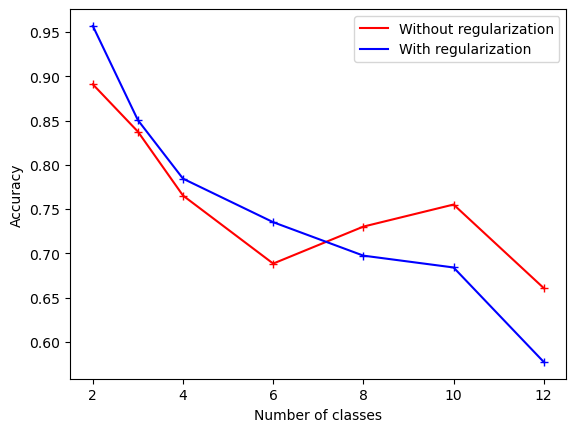

In [4]:
plt.plot(class_num, no_reg_acc_list, label='Without regularization', color='r')
plt.plot(class_num, reg_acc_list, label='With regularization', color='b')
# plot a '+' on each data point
plt.plot(class_num, no_reg_acc_list, 'r+')
plt.plot(class_num, reg_acc_list, 'b+')
plt.xlabel('Number of classes')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

array([0.1, 0.5, 1. , 1.5, 2. ])

Text(0, 0.5, 'Accuracy')

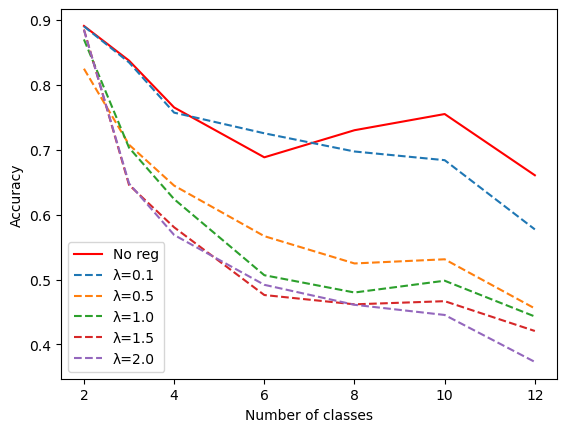

In [17]:
class_num = [2,3,4,6,8,10,12]
lambda_num = result[result['loss_function'] == 'reconstruction_loss_with_regularization']['lambda'].unique()
# no_reg_acc_list = []
# reg_acc_list = []

no_reg_acc_list = result[result['loss_function']=='reconstruction_loss_without_regularization'].groupby('n_classes').accuracy.mean()
plt.plot(class_num, no_reg_acc_list, label='No reg', color='r')

for lambda_ in lambda_num:
    reg_acc_list = result[(result['loss_function']=='reconstruction_loss_with_regularization')
              &(result['lambda']==lambda_)].groupby('n_classes').accuracy.mean()
    plt.plot(class_num, reg_acc_list, '--',
             label=f'λ={lambda_}')
plt.legend()
plt.xlabel('Number of classes')
plt.ylabel('Accuracy')